In [45]:
import tensorflow as tf
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout
import matplotlib.pyplot as plt

In [46]:
(x_train,y_train),(x_test,y_test)=mnist.load_data()

In [47]:
x_train=x_train.reshape(-1,28,28,1)/255
x_test=x_test.reshape(-1,28,28,1)/255

In [48]:
y_train=to_categorical(y_train,10)
y_test=to_categorical(y_test,10)

In [49]:
model=Sequential()

In [50]:
model.add(Conv2D(32,(3,3), activation='relu', input_shape=(28,28,1)))
model.add(MaxPooling2D((2,2)))

model.add(Conv2D(64,(3,3), activation='relu'))
model.add(MaxPooling2D((2,2)))

model.add(Flatten())

model.add(Dense(128,activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(10, activation='softmax'))

In [51]:
model.compile(optimizer='adam',loss='categorical_crossentropy', metrics=['accuracy'])

In [52]:
history=model.fit(x_train,y_train, epochs=5,batch_size=128,validation_split=0.2)

Epoch 1/5


375/375 [==============================] - 8s 17ms/step - loss: 0.3816 - accuracy: 0.8823 - val_loss: 0.0787 - val_accuracy: 0.9774
Epoch 2/5
375/375 [==============================] - 6s 16ms/step - loss: 0.1224 - accuracy: 0.9633 - val_loss: 0.0546 - val_accuracy: 0.9837
Epoch 3/5
375/375 [==============================] - 6s 16ms/step - loss: 0.0893 - accuracy: 0.9740 - val_loss: 0.0501 - val_accuracy: 0.9859
Epoch 4/5
375/375 [==============================] - 6s 16ms/step - loss: 0.0715 - accuracy: 0.9794 - val_loss: 0.0432 - val_accuracy: 0.9877
Epoch 5/5
375/375 [==============================] - 6s 16ms/step - loss: 0.0609 - accuracy: 0.9819 - val_loss: 0.0436 - val_accuracy: 0.9882


In [53]:
loss, accuracy= model.evaluate(x_test, y_test)
print(accuracy)

313/313 [==============================] - 1s 3ms/step - loss: 0.0351 - accuracy: 0.9886
0.9886000156402588


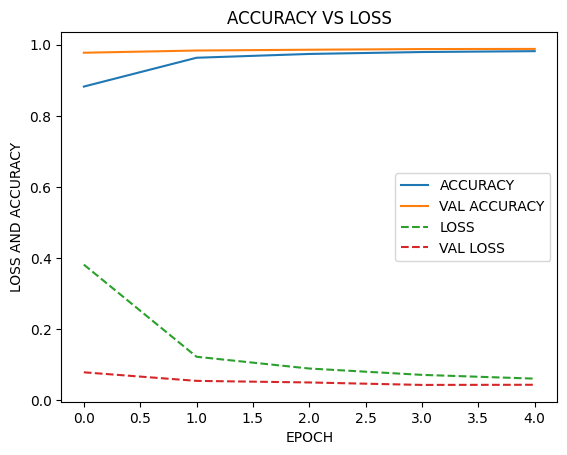

In [57]:
plt.plot(history.history['accuracy'],label='ACCURACY')
plt.plot(history.history['val_accuracy'],label='VAL ACCURACY')
plt.plot(history.history['loss'],'--',label='LOSS')
plt.plot(history.history['val_loss'],'--',label='VAL LOSS')
plt.title('ACCURACY VS LOSS')
plt.xlabel("EPOCH")
plt.ylabel("LOSS AND ACCURACY")
plt.legend()
plt.show()

In [58]:
y_pred=model.predict(x_test)

313/313 [==============================] - 1s 3ms/step


In [59]:
y_predclass=np.argmax(y_pred, axis=1)
y_true=np.argmax(y_test, axis=1)

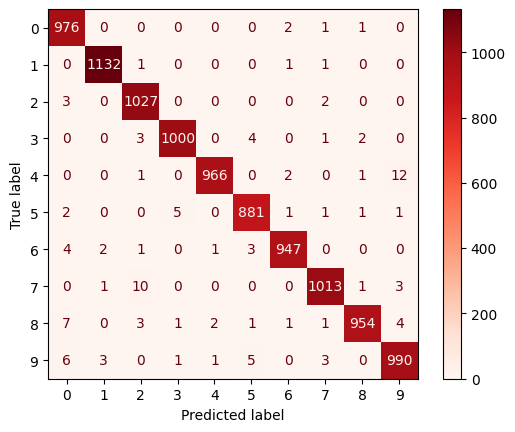

In [64]:
cm=confusion_matrix(y_true, y_predclass)
disp=ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Reds)
plt.show()